<a href="https://colab.research.google.com/github/crsah234/anyangUniverSity_Third_second/blob/main/%EC%9D%91%EC%9A%A9%ED%9A%8C%EA%B7%80%EB%B6%84%EC%84%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:


# 수면 데이터 불러오기
sleep = pd.read_sas("/content/drive/MyDrive/안양대학교_데이터처리실무(3학년2학기)/DPQ_J.xpt")

# 우울 증상 데이터 불러오기
depression = pd.read_sas("/content/drive/MyDrive/안양대학교_데이터처리실무(3학년2학기)/SLQ_J.xpt")

# 데이터 확인
display(sleep.head())
display(depression.head())

# 변수명	한글 설명	분석에서의 역할
# SEQN	조사 참여자 고유번호	두 데이터 조인
# SLD012	평일·근무일의 평소 수면시간	주요 독립변수
# SLD013	주말·비근무일의 평소 수면시간	주요 독립변수
# SLQ030	지난 12개월간 코골이 빈도	수면 특성
# SLQ040	수면 중 헐떡임·숨 막힘·호흡 중단 빈도	수면 특성
# SLQ050	의료진에게 수면 문제를 상담한 경험	수면 관련 특성
# SLQ120	지난 한 달간 낮에 지나치게 졸린 빈도	주간 졸림
# SLQ300	평일에 보통 잠드는 시각	수면 패턴
# SLQ310	평일에 보통 일어나는 시각	수면 패턴
# SLQ320	주말에 보통 잠드는 시각	수면 패턴
# SLQ330	주말에 보통 일어나는 시각	수면 패턴

# 2. 우울 증상 데이터 — DPQ_J.xpt
# 지난 2주 동안 경험한 우울 증상 빈도를 조사한 자료

# 변수명	한글 설명	분석에서의 역할
# SEQN	조사 참여자 고유번호	두 데이터 조인
# DPQ010	일상 활동에 대한 흥미나 즐거움 감소	우울 증상
# DPQ020	우울감, 침울함, 절망감	우울 증상
# DPQ030	잠들기 어려움, 수면 유지 문제 또는 과다 수면	수면 관련 증상
# DPQ040	피로감 또는 에너지 부족	우울 증상
# DPQ050	식욕 저하 또는 과식	우울 증상
# DPQ060	자신에 대한 부정적인 생각이나 실패감	우울 증상
# DPQ070	신문 읽기나 TV 시청 등에 집중하기 어려움	우울 증상
# DPQ080	움직임이나 말이 느려지거나, 반대로 안절부절못함	우울 증상
# DPQ090	죽음이나 자신을 해치는 것에 관한 생각	민감한 우울 증상 문항
# DPQ100	이러한 증상으로 인해 일상생활이 어려운 정도	기능상의 어려움

,SEQN,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,DPQ100
0,93705.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,NaN
1,93706.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,NaN
2,93708.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,NaN
3,93709.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,93711.0,1.000000e+00,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79


,SEQN,SLQ300,SLQ310,SLD012,SLQ320,SLQ330,SLD013,SLQ030,SLQ040,SLQ050,SLQ120
0,93705.0,b'23:00',b'07:00',8.0,b'23:00',b'07:00',8.0,2.0,5.397605e-79,2.0,5.397605e-79
1,93706.0,b'23:30',b'10:00',10.5,b'00:30',b'12:00',11.5,1.0,5.397605e-79,2.0,1.000000e+00
2,93708.0,b'22:30',b'06:30',8.0,b'22:30',b'06:30',8.0,9.0,5.397605e-79,2.0,2.000000e+00
3,93709.0,b'22:30',b'05:30',7.0,b'22:30',b'05:00',6.5,1.0,5.397605e-79,2.0,1.000000e+00
4,93711.0,b'22:00',b'05:00',7.0,b'23:00',b'08:00',9.0,2.0,1.000000e+00,1.0,3.000000e+00


In [ ]:
# 공통 참여자 ID인 SEQN으로 조인
df = pd.merge(
    sleep,
    depression,
    on="SEQN",
    how="inner"
)

print("수면 데이터 크기:", sleep.shape)
print("우울 데이터 크기:", depression.shape)
print("조인 후 데이터 크기:", df.shape)

display(df.head())

수면 데이터 크기: (5533, 11)
우울 데이터 크기: (6161, 11)
조인 후 데이터 크기: (5533, 21)


,SEQN,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,...,SLQ300,SLQ310,SLD012,SLQ320,SLQ330,SLD013,SLQ030,SLQ040,SLQ050,SLQ120
0,93705.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,...,b'23:00',b'07:00',8.0,b'23:00',b'07:00',8.0,2.0,5.397605e-79,2.0,5.397605e-79
1,93706.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,...,b'23:30',b'10:00',10.5,b'00:30',b'12:00',11.5,1.0,5.397605e-79,2.0,1.000000e+00
2,93708.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,...,b'22:30',b'06:30',8.0,b'22:30',b'06:30',8.0,9.0,5.397605e-79,2.0,2.000000e+00
3,93709.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,b'22:30',b'05:30',7.0,b'22:30',b'05:00',6.5,1.0,5.397605e-79,2.0,1.000000e+00
4,93711.0,1.000000e+00,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,...,b'22:00',b'05:00',7.0,b'23:00',b'08:00',9.0,2.0,1.000000e+00,1.0,3.000000e+00


In [ ]:
sleep_labels = {
    "SEQN": "조사 참여자 고유번호",
    "SLD012": "평일 수면시간",
    "SLD013": "주말 수면시간",
    "SLQ030": "코골이 빈도",
    "SLQ040": "수면 중 호흡 문제 빈도",
    "SLQ050": "수면 문제 상담 경험",
    "SLQ120": "주간 과도한 졸림 빈도",
    "SLQ300": "평일 잠드는 시각",
    "SLQ310": "평일 기상 시각",
    "SLQ320": "주말 잠드는 시각",
    "SLQ330": "주말 기상 시각"
}

# 우울 증상 데이터 변수 설명
depression_labels = {
    "SEQN": "조사 참여자 고유번호",
    "DPQ010": "흥미 및 즐거움 감소",
    "DPQ020": "우울감 및 절망감",
    "DPQ030": "수면 문제 또는 과다 수면",
    "DPQ040": "피로감 및 에너지 부족",
    "DPQ050": "식욕 저하 또는 과식",
    "DPQ060": "자신에 대한 부정적 생각",
    "DPQ070": "집중 곤란",
    "DPQ080": "움직임 변화 또는 안절부절못함",
    "DPQ090": "죽음이나 자신을 해치는 것에 관한 생각",
    "DPQ100": "증상으로 인한 일상생활의 어려움"
}

# 변수명과 한글 설명 확인
print("수면 데이터")
display(pd.DataFrame(
    list(sleep_labels.items()),
    columns=["변수명", "한글 설명"]
))

print("우울 증상 데이터")
display(pd.DataFrame(
    list(depression_labels.items()),
    columns=["변수명", "한글 설명"]
))

수면 데이터


,변수명,한글 설명
0,SEQN,조사 참여자 고유번호
1,SLD012,평일 수면시간
2,SLD013,주말 수면시간
3,SLQ030,코골이 빈도
4,SLQ040,수면 중 호흡 문제 빈도
5,SLQ050,수면 문제 상담 경험
6,SLQ120,주간 과도한 졸림 빈도
7,SLQ300,평일 잠드는 시각
8,SLQ310,평일 기상 시각
9,SLQ320,주말 잠드는 시각


우울 증상 데이터


,변수명,한글 설명
0,SEQN,조사 참여자 고유번호
1,DPQ010,흥미 및 즐거움 감소
2,DPQ020,우울감 및 절망감
3,DPQ030,수면 문제 또는 과다 수면
4,DPQ040,피로감 및 에너지 부족
5,DPQ050,식욕 저하 또는 과식
6,DPQ060,자신에 대한 부정적 생각
7,DPQ070,집중 곤란
8,DPQ080,움직임 변화 또는 안절부절못함
9,DPQ090,죽음이나 자신을 해치는 것에 관한 생각


In [ ]:
# 조인 키: SEQN
# 주요 분석 변수: 평일 수면시간 SLD012, 주말 수면시간 SLD013
# 분석 결과 변수 후보: 우울 증상 점수
# 주의: DPQ030은 수면 문제를 직접 묻는 문항이므로 수면시간과 우울 증상 간 관계를 분석할 때 이 문항을 포함한 점수와 제외한 점수를 비교하는 것이 좋아.
# 대상 연령: 수면 자료는 만 16세 이상 대상이지만, 이 우울 증상 파일은 만 18세 이상 자료만 포함하므로 조인 후 분석 대상은 성인으로 제한돼.


In [ ]:
# 1. 데이터 불러오기 및 구조 파악
print("수면 데이터 크기:", sleep.shape)
print("우울 증상 데이터 크기:", depression.shape)

display(sleep.head())
display(depression.head())

sleep.info()
depression.info()

수면 데이터 크기: (5533, 11)
우울 증상 데이터 크기: (6161, 11)


,SEQN,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,DPQ100
0,93705.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,NaN
1,93706.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,NaN
2,93708.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,NaN
3,93709.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,93711.0,1.000000e+00,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79


,SEQN,SLQ300,SLQ310,SLD012,SLQ320,SLQ330,SLD013,SLQ030,SLQ040,SLQ050,SLQ120
0,93705.0,b'23:00',b'07:00',8.0,b'23:00',b'07:00',8.0,2.0,5.397605e-79,2.0,5.397605e-79
1,93706.0,b'23:30',b'10:00',10.5,b'00:30',b'12:00',11.5,1.0,5.397605e-79,2.0,1.000000e+00
2,93708.0,b'22:30',b'06:30',8.0,b'22:30',b'06:30',8.0,9.0,5.397605e-79,2.0,2.000000e+00
3,93709.0,b'22:30',b'05:30',7.0,b'22:30',b'05:00',6.5,1.0,5.397605e-79,2.0,1.000000e+00
4,93711.0,b'22:00',b'05:00',7.0,b'23:00',b'08:00',9.0,2.0,1.000000e+00,1.0,3.000000e+00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5533 entries, 0 to 5532
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    5533 non-null   float64
 1   DPQ010  5094 non-null   float64
 2   DPQ020  5093 non-null   float64
 3   DPQ030  5093 non-null   float64
 4   DPQ040  5092 non-null   float64
 5   DPQ050  5092 non-null   float64
 6   DPQ060  5091 non-null   float64
 7   DPQ070  5091 non-null   float64
 8   DPQ080  5091 non-null   float64
 9   DPQ090  5090 non-null   float64
 10  DPQ100  3362 non-null   float64
dtypes: float64(11)
memory usage: 475.6 KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6161 entries, 0 to 6160
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    6161 non-null   float64
 1   SLQ300  6161 non-null   object 
 2   SLQ310  6161 non-null   object 
 3   SLD012  6113 non-null   float64
 4   SLQ320  6161 non-null   object 
 5 

In [ ]:
# # 조인 시 대상 연령: 수면 자료는 만 16세 이상 대상이지만, 이 우울 증상 파일은 만 18세 이상 자료만 포함하므로 조인 후 분석 대상은 성인으로 제한돼
# 확인할 내용:
# - 각 데이터의 행과 열 개수
# - 변수명과 자료형
# - 참여자 식별번호인 SEQN의 존재 여부
# - 두 데이터가 같은 조사 주기의 자료인지 확인

In [ ]:
# 2. 데이터 결합 및 중복 확인

In [ ]:
print("수면 데이터 ID 중복:", sleep["SEQN"].duplicated().sum())
print("우울 데이터 ID 중복:", depression["SEQN"].duplicated().sum())

df = pd.merge(
    sleep,
    depression,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)

print("결합 데이터 크기:", df.shape)
display(df.head())

수면 데이터 ID 중복: 0
우울 데이터 ID 중복: 0
결합 데이터 크기: (5533, 21)


,SEQN,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,...,SLQ300,SLQ310,SLD012,SLQ320,SLQ330,SLD013,SLQ030,SLQ040,SLQ050,SLQ120
0,93705.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,...,b'23:00',b'07:00',8.0,b'23:00',b'07:00',8.0,2.0,5.397605e-79,2.0,5.397605e-79
1,93706.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,...,b'23:30',b'10:00',10.5,b'00:30',b'12:00',11.5,1.0,5.397605e-79,2.0,1.000000e+00
2,93708.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,...,b'22:30',b'06:30',8.0,b'22:30',b'06:30',8.0,9.0,5.397605e-79,2.0,2.000000e+00
3,93709.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,b'22:30',b'05:30',7.0,b'22:30',b'05:00',6.5,1.0,5.397605e-79,2.0,1.000000e+00
4,93711.0,1.000000e+00,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,...,b'22:00',b'05:00',7.0,b'23:00',b'08:00',9.0,2.0,1.000000e+00,1.0,3.000000e+00


In [ ]:
# 3. 결측치 및 특수 응답값 처리
# 실제 결측치 개수
missing = df.isna().sum()

# 결측치 비율(%)
missing_rate = df.isna().mean().mul(100).round(2)

missing_table = pd.DataFrame({
    "결측치 개수": missing,
    "결측치 비율(%)": missing_rate
}).sort_values("결측치 비율(%)", ascending=False)

display(missing_table)

,결측치 개수,결측치 비율(%)
DPQ100,2171,39.24
DPQ090,443,8.01
DPQ060,442,7.99
DPQ070,442,7.99
DPQ080,442,7.99
DPQ040,441,7.97
DPQ050,441,7.97
DPQ020,440,7.95
DPQ030,440,7.95
DPQ010,439,7.93


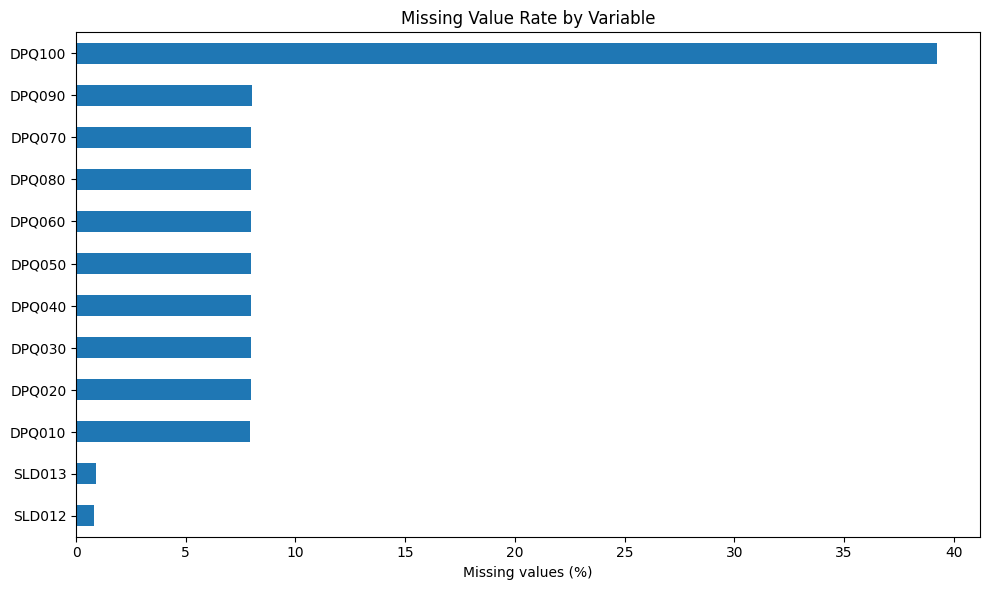

In [ ]:
# 결측치 비율 시각화:
missing_plot = missing_rate[missing_rate > 0].sort_values()

plt.figure(figsize=(10, 6))
missing_plot.plot(kind="barh")
plt.xlabel("Missing values (%)")
plt.title("Missing Value Rate by Variable")
plt.tight_layout()
plt.show()

In [ ]:
# 특수 응답값 확인
# 우울 증상 문항 DPQ010~DPQ090은 일반적으로 다음처럼 해석해.
# 값	의미
# 0	전혀 없음
# 1	며칠 동안
# 2	일주일 이상
# 3	거의 매일
# 7	응답 거절
# 9	모름


In [ ]:
# # 4. 단변량 분석 — 각 변수의 분포 확인
# 4-1. 수면시간 분석
# 주요 변수는 평일 수면시간 SLD012, 주말 수면시간 SLD013

In [ ]:
sleep_vars = ["SLD012", "SLD013"]

display(df[sleep_vars].describe().T)

,count,mean,std,min,25%,50%,75%,max
SLD012,5489.0,7.621242,1.677869,2.0,6.5,7.5,8.5,14.0
SLD013,5482.0,8.299617,1.765133,2.0,7.0,8.0,9.0,14.0


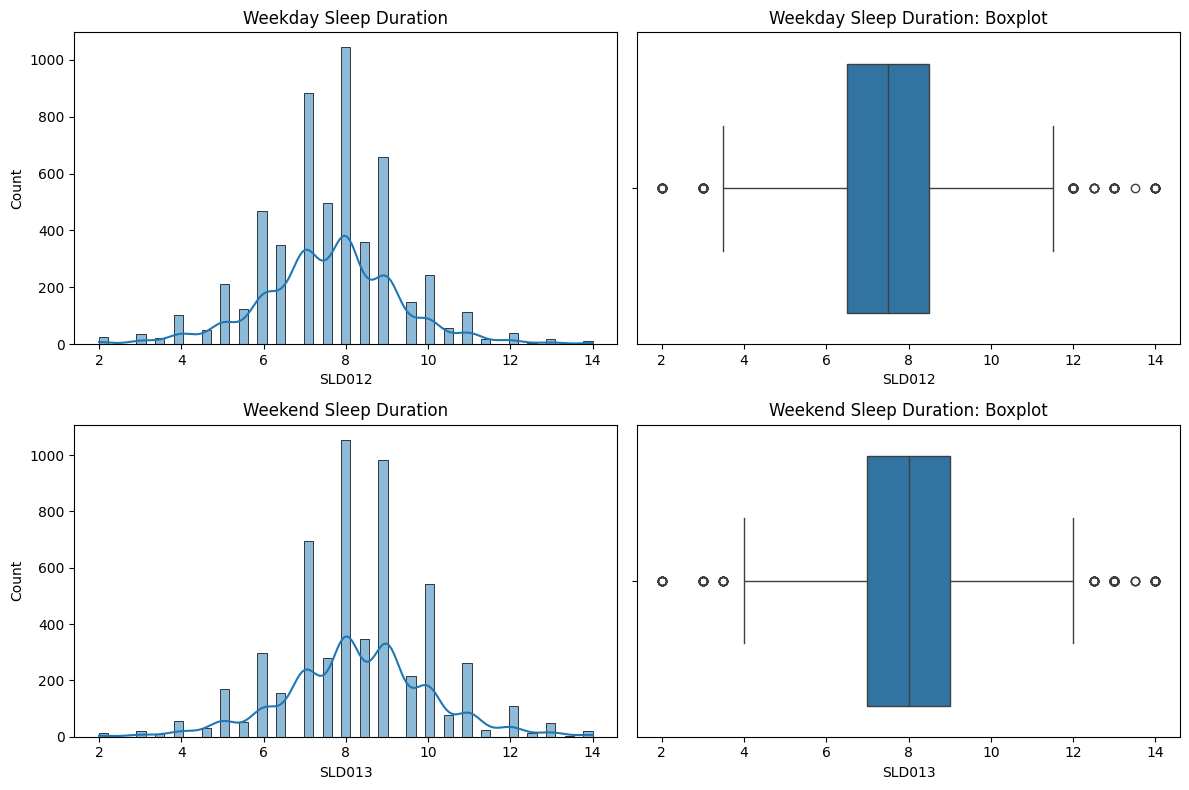

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(data=df, x="SLD012", kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Weekday Sleep Duration")

sns.boxplot(data=df, x="SLD012", ax=axes[0, 1])
axes[0, 1].set_title("Weekday Sleep Duration: Boxplot")

sns.histplot(data=df, x="SLD013", kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Weekend Sleep Duration")

sns.boxplot(data=df, x="SLD013", ax=axes[1, 1])
axes[1, 1].set_title("Weekend Sleep Duration: Boxplot")

plt.tight_layout()
plt.show()

In [ ]:
# 여기서는 다음을 확인하면 돼.
# - 수면시간이 어느 구간에 집중되는가?
# - 분포가 한쪽으로 치우쳐 있는가?
# - 일반적인 범위에서 벗어난 값이 있는가?
# - 평일과 주말 수면시간 분포가 달라 보이는가?

In [ ]:
# 4-2. 우울 증상 문항 분석
display(df[dpq_items].describe().T)

for col in dpq_items:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).sort_index())

,count,mean,std,min,25%,50%,75%,max
DPQ010,5094.0,0.399293,0.820156,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,9.0
DPQ020,5093.0,0.359317,0.766857,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,9.0
DPQ030,5093.0,0.646574,0.991107,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,9.0
DPQ040,5092.0,0.761783,0.975444,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,9.0
DPQ050,5092.0,0.399450,0.817160,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,9.0
DPQ060,5091.0,0.256728,0.700190,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,9.0
DPQ070,5091.0,0.272245,0.721909,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,9.0
DPQ080,5091.0,0.179140,0.627250,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,9.0
DPQ090,5090.0,0.061493,0.396921,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,9.0



DPQ010
DPQ010
5.397605e-79    3792
1.000000e+00     816
2.000000e+00     280
3.000000e+00     198
7.000000e+00       4
9.000000e+00       4
NaN              439
Name: count, dtype: int64

DPQ020
DPQ020
5.397605e-79    3865
1.000000e+00     831
2.000000e+00     224
3.000000e+00     167
7.000000e+00       2
9.000000e+00       4
NaN              440
Name: count, dtype: int64

DPQ030
DPQ030
5.397605e-79    3119
1.000000e+00    1141
2.000000e+00     383
3.000000e+00     443
7.000000e+00       3
9.000000e+00       4
NaN              440
Name: count, dtype: int64

DPQ040
DPQ040
5.397605e-79    2584
1.000000e+00    1612
2.000000e+00     457
3.000000e+00     432
7.000000e+00       3
9.000000e+00       4
NaN              441
Name: count, dtype: int64

DPQ050
DPQ050
5.397605e-79    3812
1.000000e+00     778
2.000000e+00     276
3.000000e+00     221
7.000000e+00       2
9.000000e+00       3
NaN              441
Name: count, dtype: int64

DPQ060
DPQ060
5.397605e-79    4237
1.000000e+00     575
2.0

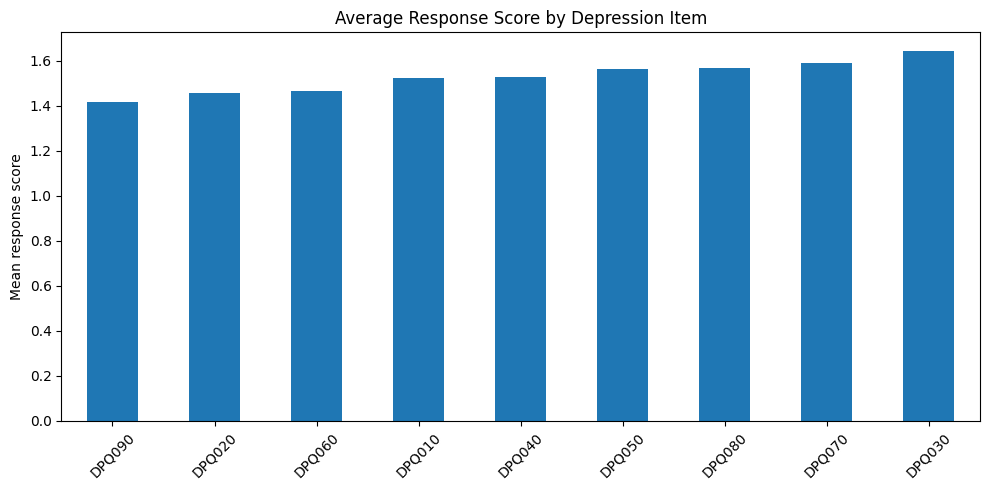

In [ ]:
# 각 문항의 응답비율
dpq_valid = df[dpq_items].where(df[dpq_items].isin([0, 1, 2, 3]))

dpq_valid.mean().sort_values().plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Mean response score")
plt.title("Average Response Score by Depression Item")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# 5. 피처 엔지니어링 — 분석용 변수 만들기

In [ ]:
# 9개 문항을 합산하면 총점은 0~27점 범위야. 다만 9개 문항 모두 유효한 응답인 경우에만 총점을 계산하자.

In [ ]:
# 우울 증상 설문 응답을 합산한 지표 / 임상적으로 우울증을 진단하는 점수는 아니야
dpq_valid = df[dpq_items].where(
    df[dpq_items].isin([0, 1, 2, 3])
)

df["depression_score"] = dpq_valid.sum(
    axis=1,
    min_count=9
)

display(df[["SEQN", "depression_score"]].head())

print(df["depression_score"].describe())
print("우울 증상 점수 결측치:", df["depression_score"].isna().sum())

,SEQN,depression_score
0,93705.0,NaN
1,93706.0,NaN
2,93708.0,NaN
3,93709.0,NaN
4,93711.0,NaN


count    36.000000
mean     18.250000
std       3.675207
min      10.000000
25%      16.000000
50%      18.000000
75%      21.250000
max      25.000000
Name: depression_score, dtype: float64
우울 증상 점수 결측치: 5497


In [ ]:
# 5-2. 평일·주말 수면시간 차이 계산
df["sleep_difference"] = df["SLD013"] - df["SLD012"]

display(
    df[["SLD012", "SLD013", "sleep_difference"]].describe().T
)

,count,mean,std,min,25%,50%,75%,max
SLD012,5489.0,7.621242,1.677869,2.0,6.5,7.5,8.5,14.0
SLD013,5482.0,8.299617,1.765133,2.0,7.0,8.0,9.0,14.0
sleep_difference,5470.0,0.682998,1.631807,-9.0,0.0,0.0,1.5,10.0


In [ ]:
# 양수: 주말에 평일보다 더 오래 잠
# 0: 평일과 주말의 수면시간이 같음
# 음수: 주말에 평일보다 적게 잠


In [ ]:
# # 6. 이변량 분석 — 수면과 우울 증상의 관계
# 6-1. 상관계수 분석

In [ ]:
analysis_df = df[
    ["SLD012", "SLD013", "sleep_difference", "depression_score"]
].dropna()

print("Pearson 상관계수")
display(analysis_df.corr(method="pearson"))

print("Spearman 상관계수")
display(analysis_df.corr(method="spearman"))

Pearson 상관계수


,SLD012,SLD013,sleep_difference,depression_score
SLD012,1.000000,0.674839,-0.472148,-0.375168
SLD013,0.674839,1.000000,0.331906,-0.385222
sleep_difference,-0.472148,0.331906,1.000000,0.019404
depression_score,-0.375168,-0.385222,0.019404,1.000000


Spearman 상관계수


,SLD012,SLD013,sleep_difference,depression_score
SLD012,1.000000,0.555556,-0.389881,-0.351176
SLD013,0.555556,1.000000,0.433327,-0.362354
sleep_difference,-0.389881,0.433327,1.000000,0.072245
depression_score,-0.351176,-0.362354,0.072245,1.000000


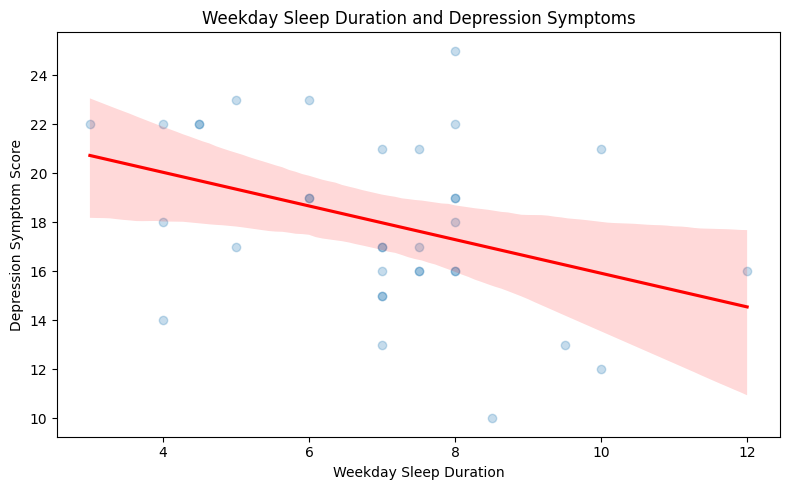

In [ ]:
# 6-2. 산점도와 추세선
plt.figure(figsize=(8, 5))

sns.regplot(
    data=analysis_df,
    x="SLD012",
    y="depression_score",
    scatter_kws={"alpha": 0.25},
    line_kws={"color": "red"}
)

plt.xlabel("Weekday Sleep Duration")
plt.ylabel("Depression Symptom Score")
plt.title("Weekday Sleep Duration and Depression Symptoms")
plt.tight_layout()
plt.show()

In [ ]:
# 확인할 내용:
# - 수면시간이 늘어날 때 우울 증상 점수가 낮아지는 경향이 있는가?
# - 관계가 직선 형태에 가까운가?
# - 특정 수면시간 구간에서 점수 분포가 넓어지는가?



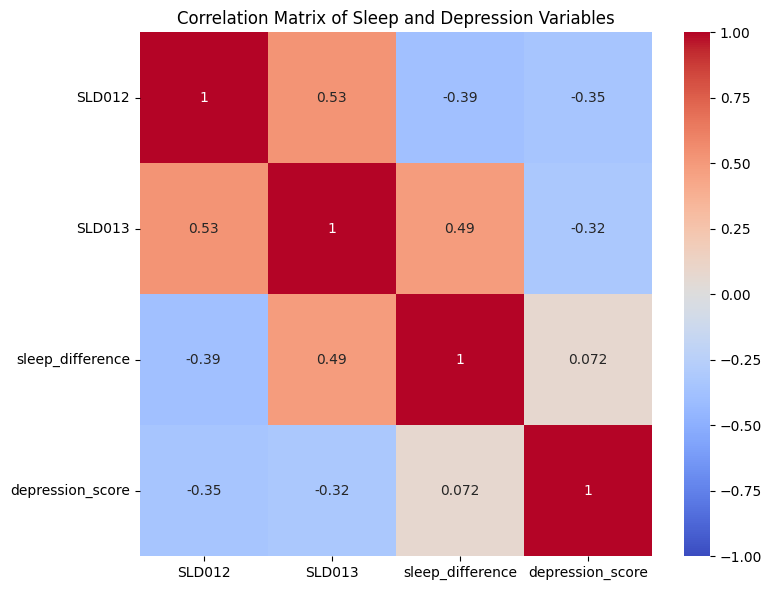

In [ ]:
# 7. 다변량 분석 — 수면 변수 여러 개 함께 비교
multi_vars = [
    "SLD012",
    "SLD013",
    "sleep_difference",
    "depression_score"
]

corr_matrix = df[multi_vars].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Sleep and Depression Variables")
plt.tight_layout()
plt.show()

In [ ]:
# 이 상관행렬을 통해 다음을 확인해.
# - 평일과 주말 수면시간은 얼마나 관련되어 있는가?
# - 평일 수면시간과 우울 증상 점수의 관계는 어떠한가?
# - 주말 수면시간과 우울 증상 점수의 관계는 어떠한가?
# - 수면시간 차이와 우울 증상 점수는 관련되어 있는가?



In [ ]:
# 8. 이상치 탐지
for col in ["SLD012", "SLD013"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df.loc[
        df[col].notna() & ~df[col].between(lower, upper),
        col
    ]

    print(f"{col} 이상치 개수:", len(outliers))
    print(f"하한: {lower:.2f}, 상한: {upper:.2f}")

SLD012 이상치 개수: 140
하한: 3.50, 상한: 11.50
SLD013 이상치 개수: 130
하한: 4.00, 상한: 12.00


In [ ]:
# 9. 정규성·왜도·분포 형태 확인
from scipy.stats import skew

for col in ["SLD012", "SLD013", "depression_score"]:
    values = df[col].dropna()

    print(f"\n[{col}]")
    print("왜도:", round(skew(values), 3))
    print("고유값 개수:", values.nunique())


[SLD012]
왜도: 0.002
고유값 개수: 24

[SLD013]
왜도: -0.03
고유값 개수: 24

[depression_score]
왜도: -0.09
고유값 개수: 14


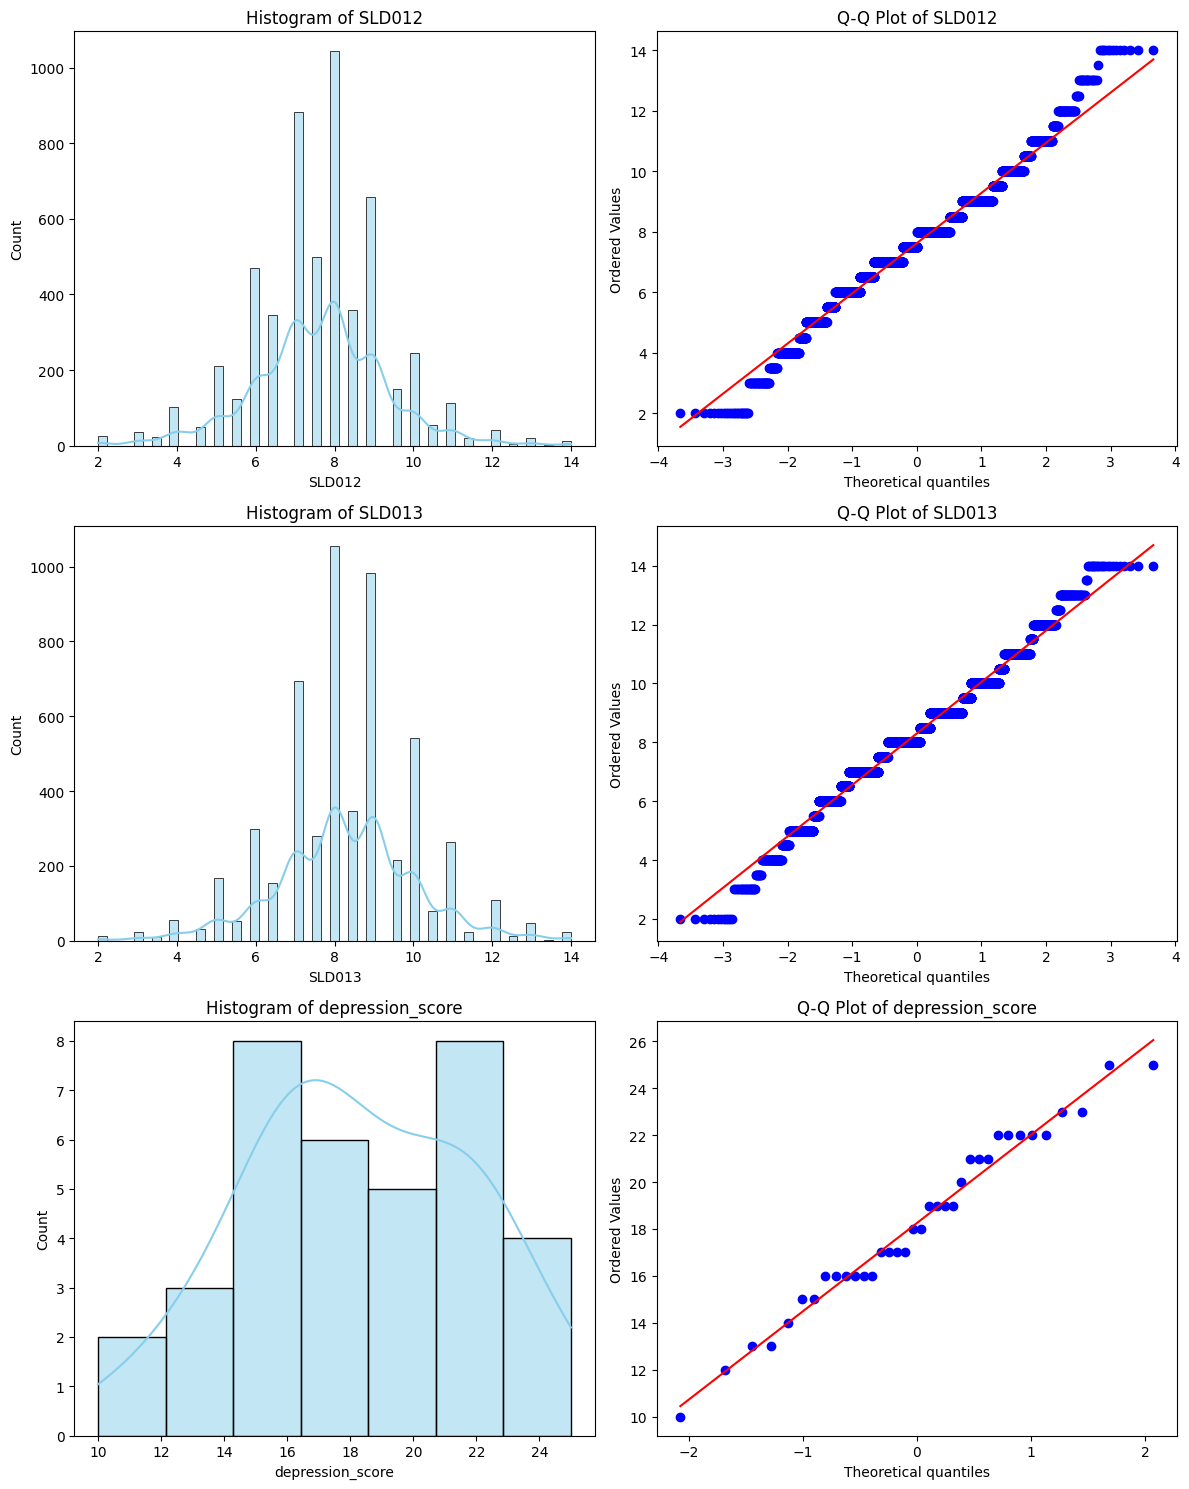

In [ ]:
# 10. 최종 결론 및 발표 구성
# 순서	발표 내용	답해야 할 질문
# 1	문제 정의	수면시간과 우울 증상은 관련이 있는가?
# 2	데이터 구조	두 설문 데이터는 어떤 변수로 구성되는가?
# 3	데이터 정제	결측치와 특수 응답값을 어떻게 처리했는가?
# 4	단변량 분석	수면시간과 우울 증상 점수는 어떻게 분포하는가?
# 5	이변량 분석	두 변수 사이에 어떤 관계가 나타나는가?
# 6	다변량 분석	평일·주말 수면시간과 수면시간 차이는 각각 어떤 관계를 보이는가?
# 7	한계 및 결론	결과를 어디까지 해석할 수 있는가?

In [ ]:
# # 마지막으로, 두 데이터는 같은 조사 주기의 자료이지만 실제 결합 분석에서는 공통 응답자만 남고, 두 설문의 응답 대상 연령 조건도 확인해야 해.
# 또한 NHANES는 표본조사이므로 모집단 수준의 추론을 하려면 조사 가중치와 표본설계를 고려해야 한다는 점도 한계에 포함하면 좋아.
# # 추천 진행 순서: 우선 1~3단계 코드를 실행해서 데이터 크기, 결측치, 특수 응답값을 확인하자.
# 그 결과를 바탕으로 4단계 이후 분석을 진행하면, 실제 데이터에 맞는 EDA를 만들 수 있어